# Занятие 12. Деревья решений и ансамбли

## 1. Обучение и визуализация дерева решений

Используем набор данных breast_cancer, содержащий признаки опухолей и два класса: злокачественные и доброкачественные. Разделим данные на обучающую (80%) и тестовую (20%) выборки.

Дерево решений последовательно разделяет объекты по значениям признаков. В конечных узлах (листьях) определяется класс объекта. Для выбора разбиения используем критерий Джини:

$$G=1-\sum_{i=1}^{K}p_i^2,$$

где $K$ — количество классов, $p_i$ — доля объектов класса $i$ в узле. Чем меньше значение критерия, тем однороднее узел.

Для оценки качества используем accuracy — долю правильно классифицированных объектов:

$$Accuracy=\frac{N_{correct}}{N}.$$

Accuracy на обучающей выборке: 1.0
Accuracy на тестовой выборке: 0.9122807017543859


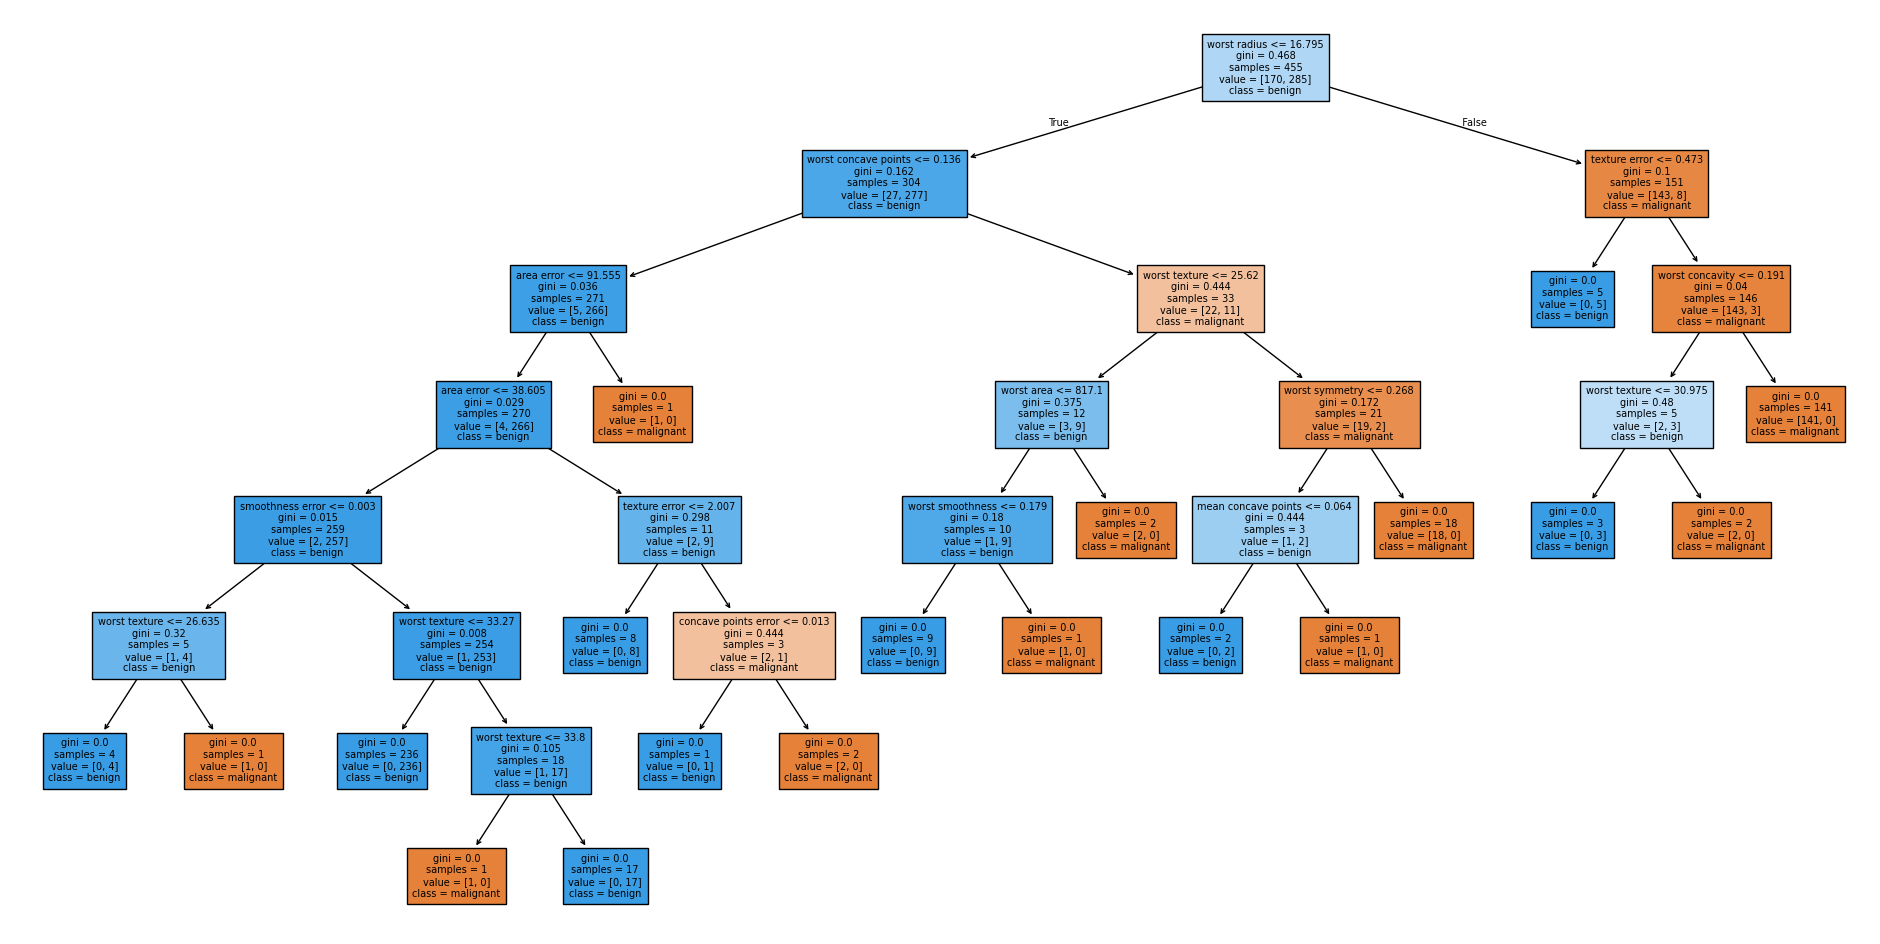

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score
from time import perf_counter

data = load_breast_cancer()
X, y = data.data, data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = DecisionTreeClassifier(random_state=42)
model.fit(X_train, y_train)
predictions = model.predict(X_test)

print('Accuracy на обучающей выборке:', model.score(X_train, y_train))
print('Accuracy на тестовой выборке:', accuracy_score(y_test, predictions))

plt.figure(figsize=(24, 12))
plot_tree(model, feature_names=data.feature_names,
          class_names=data.target_names, filled=True, fontsize=7)
plt.show()

## 2. Подбор параметров дерева

Переобучение возникает, когда модель хорошо запоминает обучающие данные, но хуже работает на новых объектах. Для ограничения сложности дерева подберём два параметра:

- max_depth — максимальная глубина дерева;
- min_samples_leaf — минимальное количество объектов в листе.

Используем GridSearchCV с кросс-валидацией на 5 частях. Метод перебирает комбинации параметров и выбирает ту, у которой средняя accuracy на проверочных частях обучающей выборки выше. Тестовая выборка в подборе не участвует.

In [ ]:
param_grid = {
    'max_depth': [2, 3, 4, 5, None],
    'min_samples_leaf': [1, 2, 5, 10]
}

model = DecisionTreeClassifier(random_state=42)
grid_search = GridSearchCV(
    model,
    param_grid,
    scoring='accuracy',
    cv=5,
    n_jobs=-1
)
grid_search.fit(X_train, y_train)

best_tree = grid_search.best_estimator_
tree_accuracy = accuracy_score(y_test, best_tree.predict(X_test))

print('Лучшие параметры:', grid_search.best_params_)
print('Лучшая средняя accuracy при кросс-валидации:', grid_search.best_score_)
print('Accuracy настроенного дерева на обучающей выборке:', best_tree.score(X_train, y_train))
print('Accuracy настроенного дерева на тестовой выборке:', tree_accuracy)

Лучшие параметры: {'max_depth': 4, 'min_samples_leaf': 1}
Лучшая средняя accuracy при кросс-валидации: 0.9384615384615385
Accuracy настроенного дерева на обучающей выборке: 0.9868131868131869
Accuracy настроенного дерева на тестовой выборке: 0.9385964912280702


## 3. Обучение случайного леса

Ансамбль — объединение нескольких моделей. В Random Forest деревья обучаются на случайных выборках с возвращением, а при разбиении рассматривается случайное подмножество признаков. Класс определяется по максимальной средней вероятности класса по всем деревьям.

Обучим случайный лес из 100 деревьев и сравним его с настроенным деревом на одной тестовой выборке. Время обучения измерим для дополнительного задания.

In [ ]:
forest = RandomForestClassifier(n_estimators=100, random_state=42)
start = perf_counter()
forest.fit(X_train, y_train)
forest_time = perf_counter() - start

forest_accuracy = accuracy_score(y_test, forest.predict(X_test))

print('Accuracy настроенного дерева:', tree_accuracy)
print('Accuracy случайного леса:', forest_accuracy)

Accuracy настроенного дерева: 0.9385964912280702
Accuracy случайного леса: 0.956140350877193


## 4. Важность признаков


Важность признака определяется тем, насколько сильно он уменьшает неоднородность узлов дерева по критерию Джини.

Взвешенное уменьшение неоднородности при разбиении узла:

$$
\Delta G_t = \frac{N_t}{N}\left(G_t-\frac{N_L}{N_t}G_L-\frac{N_R}{N_t}G_R\right)
$$

где:
- $N$ — количество объектов в корне дерева;
- $N_t$ — количество объектов в текущем узле;
- $N_L$, $N_R$ — количество объектов в левом и правом дочерних узлах;
- $G_t$ — критерий Джини до разбиения;
- $G_L$, $G_R$ — критерии Джини дочерних узлов.

Вклад признака $j$ в одном дереве рассчитывается как сумма уменьшений неоднородности по всем узлам, в которых использовался этот признак:

$$
I_j=\sum_{t:\,f(t)=j}\Delta G_t
$$

Нормируем полученные значения, то есть делим вклад каждого признака на сумму вкладов всех признаков в данном дереве.

Итоговая важность признака в случайном лесе рассчитывается усреднением его важности по всем деревьям

Чем больше значение важности, тем больший вклад признак вносит в уменьшение неоднородности. Сумма важностей всех признаков равна 1.

Для автоматического расчёта используется атрибут `feature_importances_`.

worst area              0.140016
worst concave points    0.129530
worst radius            0.097696
mean concave points     0.090885
worst perimeter         0.072226
dtype: float64


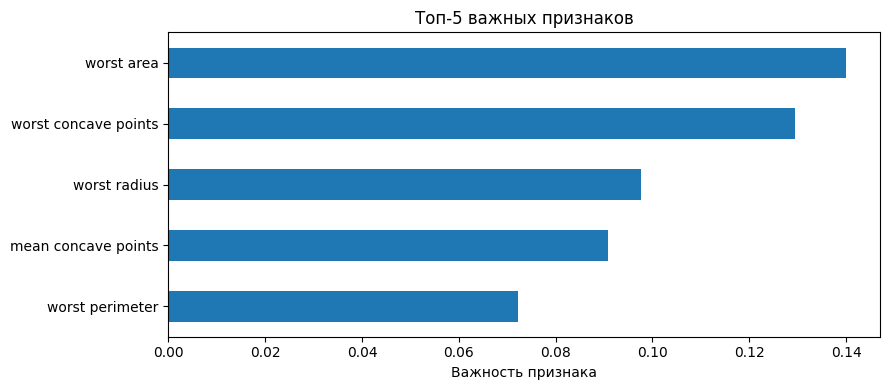

In [ ]:
importance = pd.Series(forest.feature_importances_, index=data.feature_names)
top5 = importance.sort_values(ascending=False).head(5)
print(top5)

plt.figure(figsize=(9, 4))
top5.sort_values().plot(kind='barh')
plt.xlabel('Важность признака')
plt.title('Топ-5 важных признаков')
plt.tight_layout()
plt.show()

## Дополнительное задание. Градиентный бустинг

Градиентный бустинг — ансамбль, в котором деревья строятся последовательно. Каждое новое дерево приближает отрицательный градиент функции потерь, помогая уменьшить ошибки предыдущей модели.

Обучим GradientBoostingClassifier со 100 деревьями и сравним accuracy и время обучения со случайным лесом. Время измеряем только для метода fit, без предсказаний.

Как работает алгоритм?
1. Делаем начальное предсказание.
2. Оцениваем ошибки с помощью функции потерь (Log Loss).
3. Рассчитываем отрицательный градиент — определяем, в какую сторону и насколько необходимо скорректировать предсказания.
4. Обучаем дерево регрессии. Оно получает исходные признаки объектов и отрицательные градиенты в качестве целевых значений. На их основе дерево формирует поправки.
5. Обновляем предсказания, добавляя рассчитанные поправки с учётом скорости обучения.
6. Повторяем процедуру для следующего дерева. В нашей практике строится 100 деревьев.

In [ ]:
boosting = GradientBoostingClassifier(n_estimators=100, random_state=42)
start = perf_counter()
boosting.fit(X_train, y_train)
boosting_time = perf_counter() - start

boosting_accuracy = accuracy_score(y_test, boosting.predict(X_test))

results = pd.DataFrame({
    'Модель': ['Random Forest', 'Gradient Boosting'],
    'Accuracy': [forest_accuracy, boosting_accuracy],
    'Время обучения, с': [forest_time, boosting_time]
})
print(results.to_string(index=False))

           Модель  Accuracy  Время обучения, с
    Random Forest   0.95614           0.710061
Gradient Boosting   0.95614           1.895001


После подбора гиперпараметров дерева решений переобучение уменьшилось, а точность выросла с 91,23% до 93,86%. Случайный лес и градиентный бустинг показали одинаковую точность — 95,61%. При этом случайный лес обучался в 2,7 раза быстрее, поэтому в данном эксперименте оказался наиболее эффективным методом.